<a href="https://colab.research.google.com/github/kamilabalabatyr/AI-Fundamentals/blob/main/Lab1_DryBean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ucimlrepo -q

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

np.random.seed(42)
torch.manual_seed(42)

In [ ]:
from ucimlrepo import fetch_ucirepo

dry_bean = fetch_ucirepo(id=602)
df = dry_bean.data.original.copy()

print("Size of the dataset: ", df.shape)
print("Columns: ", list(df.columns))
df.head()

Size of the dataset:  (13611, 17)
Columns:  ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [ ]:
print("Missing values in each column: ")
print(df.isnull().sum())

print("\nNumber of duplicates: ", df.duplicated().sum())

Missing values in each column: 
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRatio        0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
Roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Number of duplicates:  68


In [ ]:
df = df.drop_duplicates().reset_index(drop=True)
print("Size after removing duplicates: ", df.shape)

Size after removing duplicates:  (13543, 17)


Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Percentage: 
Class
DERMASON    26.18
SIRA        19.46
SEKER       14.97
HOROZ       13.73
CALI        12.04
BARBUNYA     9.76
BOMBAY       3.85
Name: count, dtype: float64


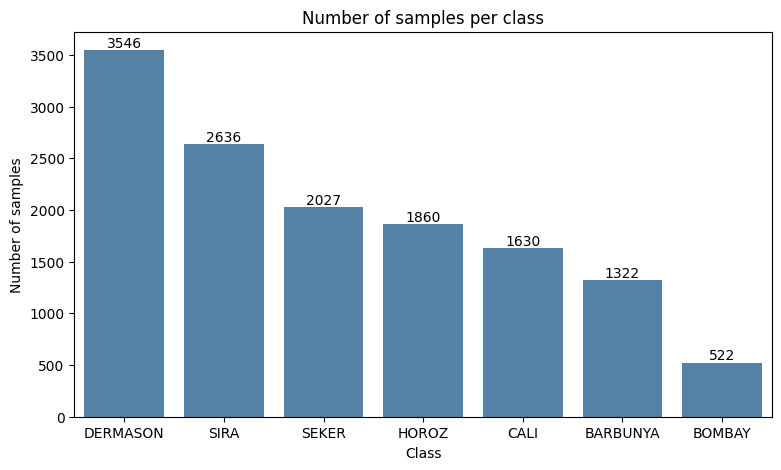

In [ ]:
class_counts = df['Class'].value_counts()
print(class_counts)
print("\nPercentage: ")
print((class_counts / len(df)*100).round(2))

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=class_counts.index, y=class_counts.values, color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Number of samples per class")
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.show()

In [ ]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Area,13543.0,53048.460,29392.438,20420.000,36282.500,44580.000,61382.000,254616.000
Perimeter,13543.0,854.993,214.723,524.736,703.230,793.896,977.147,1985.370
MajorAxisLength,13543.0,319.896,85.809,183.601,253.087,296.405,376.312,738.860
MinorAxisLength,13543.0,202.365,45.052,122.513,175.886,192.491,217.245,460.198
AspectRatio,13543.0,1.581,0.245,1.025,1.431,1.550,1.704,2.430
Eccentricity,13543.0,0.750,0.092,0.219,0.715,0.764,0.810,0.911
ConvexArea,13543.0,53767.987,29844.249,20684.000,36673.000,45122.000,62360.000,263261.000
EquivDiameter,13543.0,253.034,59.308,161.244,214.933,238.246,279.560,569.374
Extent,13543.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,13543.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


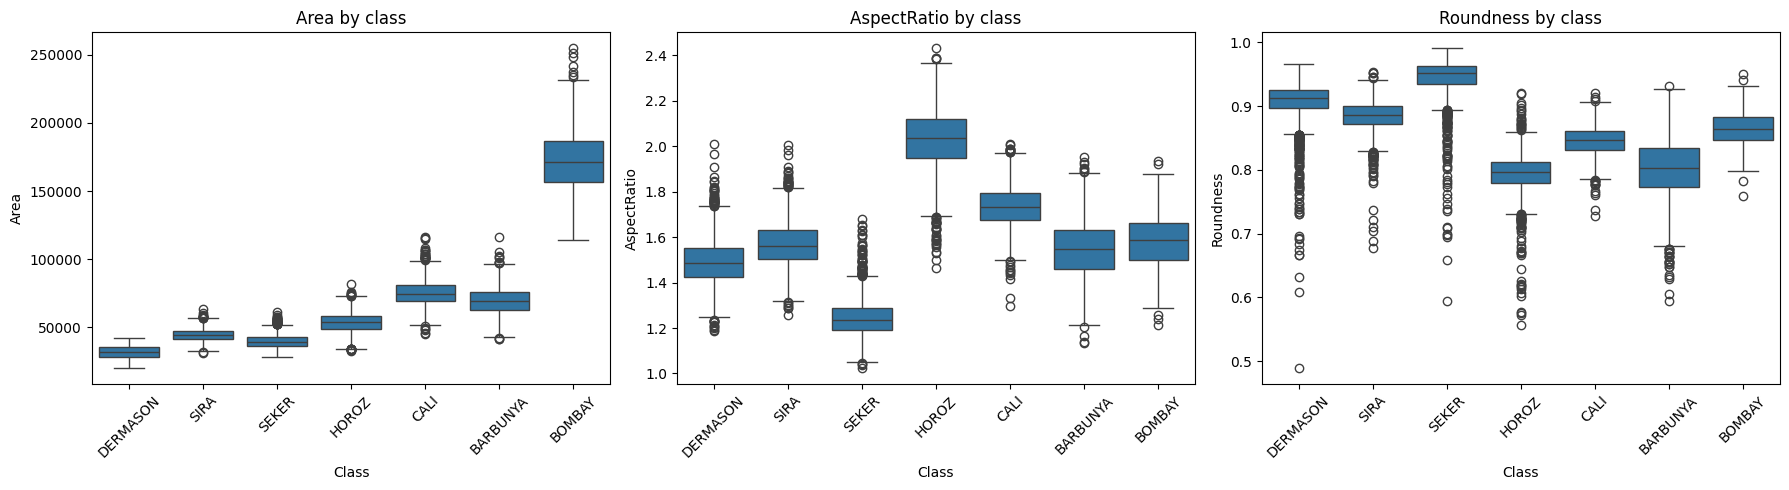

In [ ]:
features = ['Area', 'AspectRatio', 'Roundness']
order = class_counts.index

fig, axes = plt.subplots(1, 3, figsize=(18,5))
for ax, feat in zip(axes, features):
  sns.boxplot(data=df, x='Class', y=feat, order=order, ax=ax)
  ax.set_title(f"{feat} by class")
  ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.preprocessing import LabelEncoder

X = df.drop(columns='Class').values
y_text = df['Class'].values

encoder = LabelEncoder()
y = encoder.fit_transform(y_text)

print("X shape: ", X.shape)
print("y shape: ", y.shape)

for i,name in enumerate(encoder.classes_):
  print(i, "->", name)

X shape:  (13543, 16)
y shape:  (13543,)
0 -> BARBUNYA
1 -> BOMBAY
2 -> CALI
3 -> DERMASON
4 -> HOROZ
5 -> SEKER
6 -> SIRA


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print("Train shape: ", X_train.shape, "Test shape: ", X_test.shape, "Val shape: ", X_val.shape, )

Train shape:  (9480, 16) Test shape:  (2032, 16) Val shape:  (2031, 16)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_val_scaled = scaler.transform(X_val)

print("Train mean (first 5 features):", X_train_scaled.mean(axis=0)[:5].round(3))
print("Train std  (first 5 features):", X_train_scaled.std(axis=0)[:5].round(3))

Train mean (first 5 features): [ 0. -0. -0. -0.  0.]
Train std  (first 5 features): [1. 1. 1. 1. 1.]


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

def make_loader(X, y, batch_size=64, shuffle=False):
  ds = TensorDataset(torch.tensor(X, dtype=torch.float32),
                     torch.tensor(y, dtype=torch.long))
  return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

class MLP(nn.Module):
  def __init__(self, hidden=[32,16], n_in=16, n_out=7):
    super().__init__()
    layers = []
    prev = n_in
    for h in hidden:
      layers += [nn.Linear(prev, h), nn.ReLU()]
      prev = h
    layers.append(nn.Linear(prev, n_out))
    self.net = nn.Sequential(*layers)

  def forward(self, x):
    return self.net(x)

print(MLP())


MLP(
  (net): Sequential(
    (0): Linear(in_features=16, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=7, bias=True)
  )
)


In [ ]:
def train_model(X_tr, y_tr, X_v, y_v, hidden=[32,16], epochs=50, lr=1e-3, seed=42, opt_name='adam', momentum=0.0):
  torch.manual_seed(seed)
  model = MLP(hidden)
  loss_fn = nn.CrossEntropyLoss()
  if opt_name == 'adam':
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
  else:
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)
  train_loader = make_loader(X_tr, y_tr, shuffle=True)
  val_loader = make_loader(X_v, y_v)

  hist = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}

  def evaluate(loader):
    model.eval()
    total_loss, correct, n = 0,0,0
    with torch.no_grad():
      for xb, yb in loader:
        out = model(xb)
        total_loss += loss_fn(out, yb).item()*len(xb)
        correct += (out.argmax(1) == yb).sum().item()
        n += len(xb)
    return total_loss/n, correct/n

  for epoch in range(epochs):
    model.train()
    for xb, yb in train_loader:
      optimizer.zero_grad()
      loss = loss_fn(model(xb), yb)
      loss.backward()
      optimizer.step()

    tr_loss, tr_acc = evaluate(make_loader(X_tr, y_tr))
    v_loss, v_acc = evaluate(val_loader)
    hist['train_loss'].append(tr_loss); hist['train_acc'].append(tr_acc)
    hist['val_loss'].append(v_loss); hist['val_acc'].append(v_acc)

  return model, hist

In [ ]:
model_raw, hist_raw = train_model(X_train, y_train, X_val, y_val)
model_sc, hist_sc = train_model(X_train_scaled, y_train, X_val_scaled, y_val)

def first_epoch_reaching(hist, level=0.90):
  for i, acc in enumerate(hist['val_acc']):
    if acc >= level:
      return i+1
  return "never"

for name, h in [("Unscaled", hist_raw), ("Standardized", hist_sc)]:
  print(f"{name:13s} | train loss: {h['train_loss'][-1]:.4f} | val loss: {h['val_loss'][-1]:.4f} "
          f"| val acc: {h['val_acc'][-1]:.4f} | epoch to 90% val acc: {first_epoch_reaching(h)}")

Unscaled      | train loss: 2.5613 | val loss: 2.6387 | val acc: 0.5687 | epoch to 90% val acc: never
Standardized  | train loss: 0.1671 | val loss: 0.2073 | val acc: 0.9276 | epoch to 90% val acc: 3


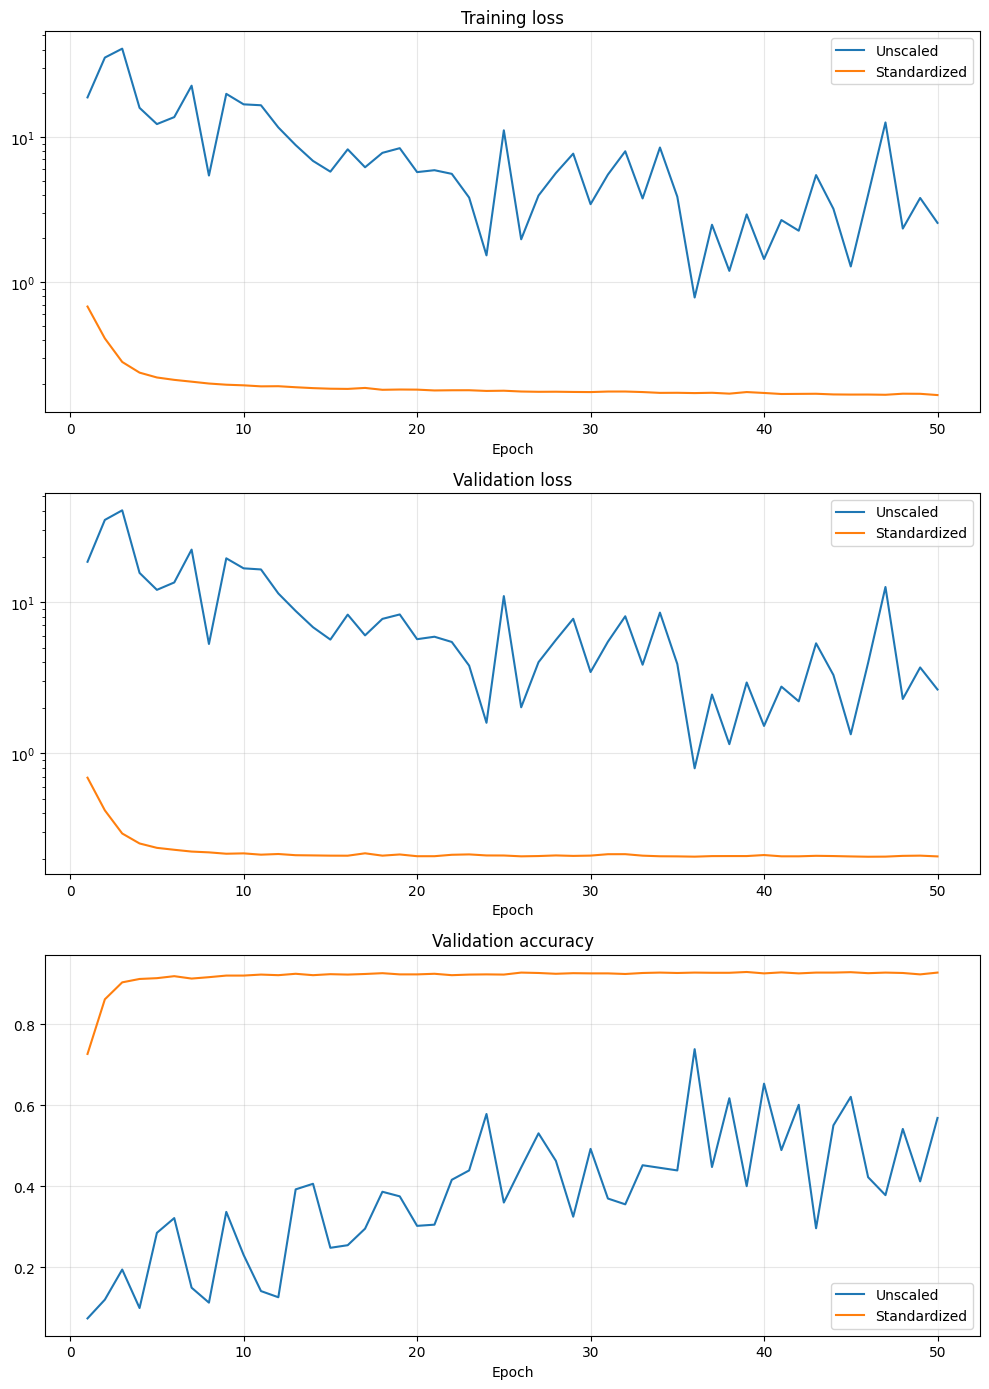

In [ ]:
epochs = range(1, len(hist_raw['train_loss'])+1)
figs, axes = plt.subplots(3, 1, figsize=(10,14))

for key, ax, title in [('train_loss', axes[0], 'Training loss'),('val_loss', axes[1], 'Validation loss'), ('val_acc', axes[2], 'Validation accuracy')]:
  ax.plot(epochs, hist_raw[key], label='Unscaled')
  ax.plot(epochs, hist_sc[key],  label='Standardized')
  ax.set_title(title); ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=0.3)
  if 'loss' in key:
    ax.set_yscale('log')

plt.tight_layout()
plt.show()

In [ ]:
baseline = MLP([32,16])
print(baseline)

total = 0
for name, p in baseline.named_parameters():
  print(f"{name:15s} shape: {str(list(p.shape)):10s} params: {p.numel()}")
  total += p.numel()

print("\nTotal trainable parameters:", total)
print("Check:", sum(p.numel() for p in baseline.parameters() if p.requires_grad))

MLP(
  (net): Sequential(
    (0): Linear(in_features=16, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=7, bias=True)
  )
)
net.0.weight    shape: [32, 16]   params: 512
net.0.bias      shape: [32]       params: 32
net.2.weight    shape: [16, 32]   params: 512
net.2.bias      shape: [16]       params: 16
net.4.weight    shape: [7, 16]    params: 112
net.4.bias      shape: [7]        params: 7

Total trainable parameters: 1191
Check: 1191


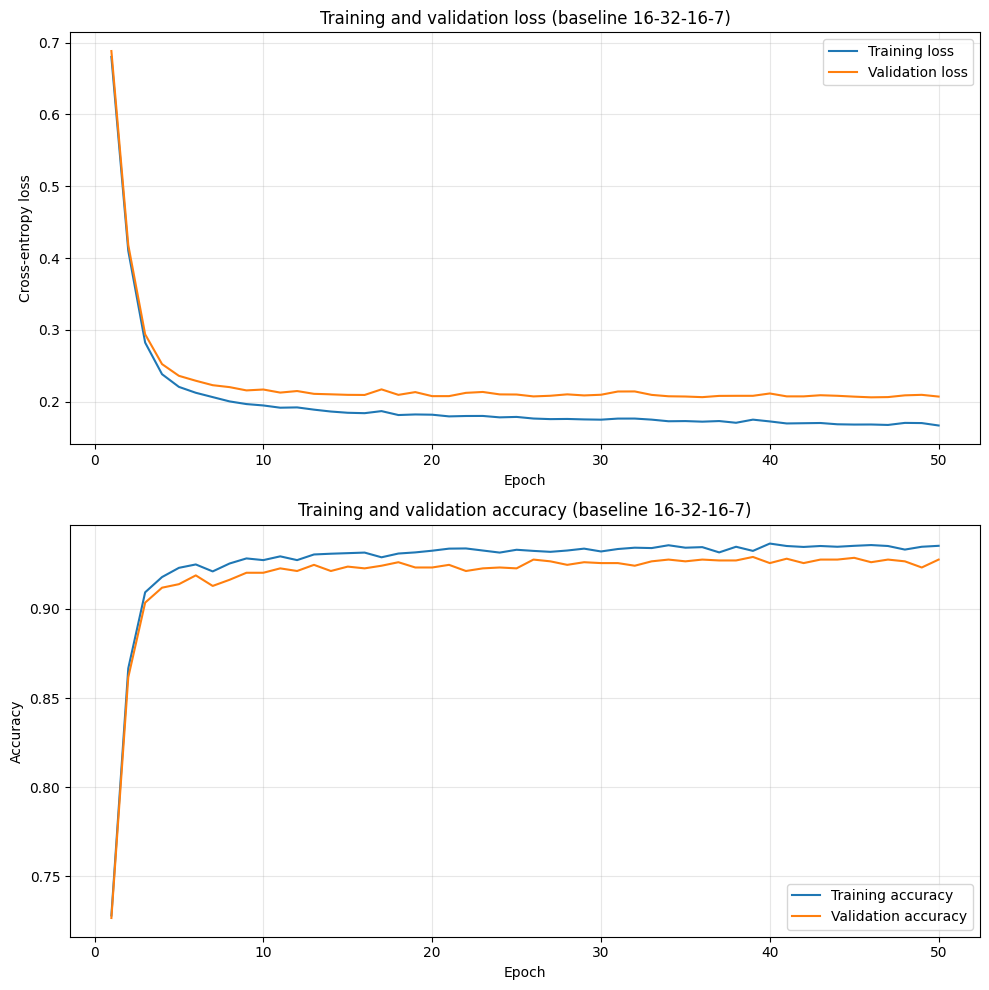

Best val loss: 0.2063 at epoch 46
Final: train loss 0.1671, val loss 0.2073
Final: train acc 0.9353, val acc 0.9276
Gap (val loss - train loss): 0.0403


In [ ]:
epochs = range(1, len(hist_sc['train_loss']) + 1)
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

axes[0].plot(epochs, hist_sc['train_loss'], label='Training loss')
axes[0].plot(epochs, hist_sc['val_loss'],   label='Validation loss')
axes[0].set_title('Training and validation loss (baseline 16-32-16-7)')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Cross-entropy loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs, hist_sc['train_acc'], label='Training accuracy')
axes[1].plot(epochs, hist_sc['val_acc'],   label='Validation accuracy')
axes[1].set_title('Training and validation accuracy (baseline 16-32-16-7)')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

best = int(np.argmin(hist_sc['val_loss']))
print(f"Best val loss: {hist_sc['val_loss'][best]:.4f} at epoch {best + 1}")
print(f"Final: train loss {hist_sc['train_loss'][-1]:.4f}, val loss {hist_sc['val_loss'][-1]:.4f}")
print(f"Final: train acc {hist_sc['train_acc'][-1]:.4f}, val acc {hist_sc['val_acc'][-1]:.4f}")
print(f"Gap (val loss - train loss): {hist_sc['val_loss'][-1] - hist_sc['train_loss'][-1]:.4f}")

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import time

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32)).argmax(1).numpy()

architectures = {
    'Model A (16-12-7)':           [12],
    'Model B (16-32-16-7)':        [32, 16],
    'Model C (16-256-128-64-7)':   [256, 128, 64],
}

results, histories, models = [], {}, {}
for name, hidden in architectures.items():
    start = time.time()
    model, hist = train_model(X_train_scaled, y_train, X_val_scaled, y_val,
                              hidden=hidden, epochs=50)
    train_time = time.time() - start

    y_pred = predict(model, X_val_scaled)
    results.append({
        'Model': name,
        'Parameters': sum(p.numel() for p in model.parameters()),
        'Val accuracy': accuracy_score(y_val, y_pred),
        'Val Macro F1': f1_score(y_val, y_pred, average='macro'),
        'Epochs trained': 50,
        'Best epoch (min val loss)': int(np.argmin(hist['val_loss'])) + 1,
        'Final train loss': hist['train_loss'][-1],
        'Final val loss': hist['val_loss'][-1],
        'Time (s)': train_time,
    })
    histories[name], models[name] = hist, model

results_df = pd.DataFrame(results)
results_df.round(4)

,Model,Parameters,Val accuracy,Val Macro F1,Epochs trained,Best epoch (min val loss),Final train loss,Final val loss,Time (s)
0,Model A (16-12-7),295,0.9232,0.9331,50,46,0.1878,0.2109,25.3842
1,Model B (16-32-16-7),1191,0.9276,0.9364,50,46,0.1671,0.2073,19.0693
2,Model C (16-256-128-64-7),45959,0.9261,0.9372,50,9,0.1328,0.2342,27.5350


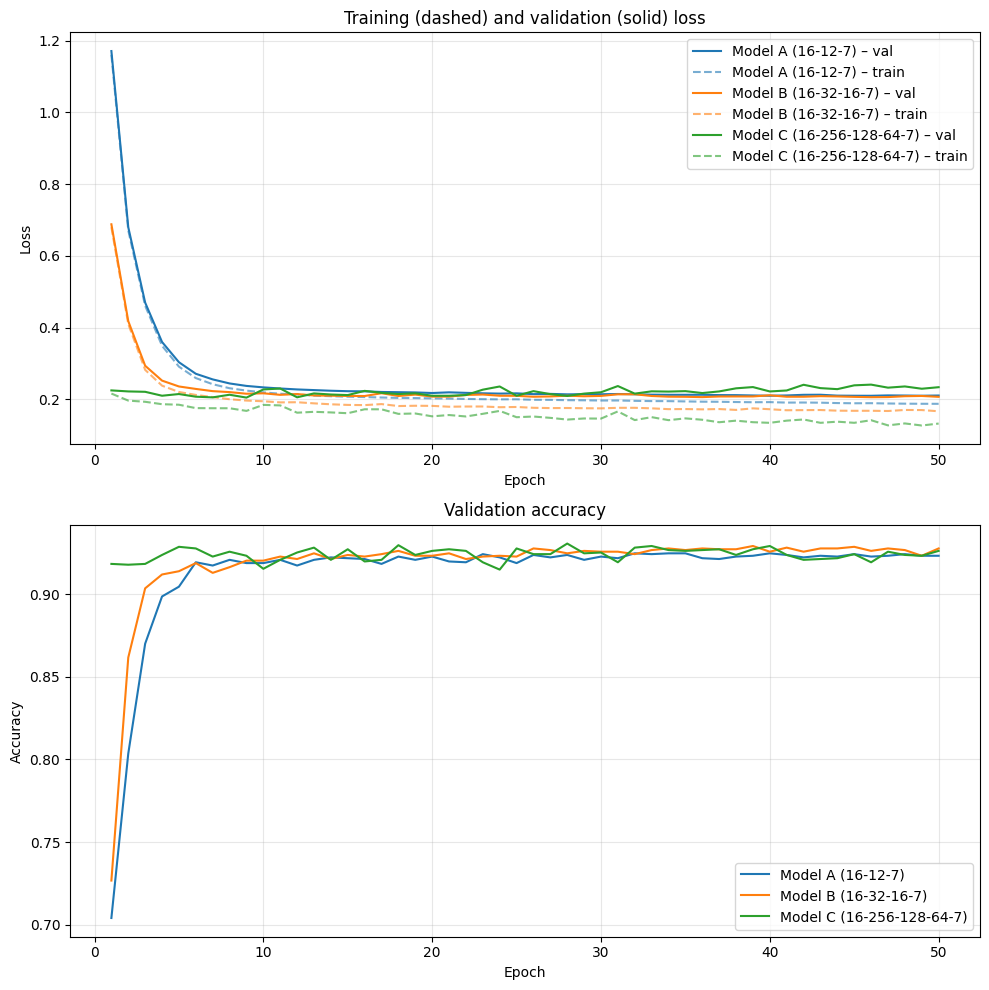

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))
for name, hist in histories.items():
    ep = range(1, len(hist['val_loss']) + 1)
    line, = axes[0].plot(ep, hist['val_loss'], label=f'{name} – val')
    axes[0].plot(ep, hist['train_loss'], '--', color=line.get_color(), alpha=0.6,
                 label=f'{name} – train')
    axes[1].plot(ep, hist['val_acc'], label=name)

axes[0].set_title('Training (dashed) and validation (solid) loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[1].set_title('Validation accuracy')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

final_model = models['Model B (16-32-16-7)']
y_test_pred = predict(final_model, X_test_scaled)
class_names = encoder.classes_

print(f"Test accuracy:   {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Macro Precision: {precision_score(y_test, y_test_pred, average='macro'):.4f}")
print(f"Macro Recall:    {recall_score(y_test, y_test_pred, average='macro'):.4f}")
print(f"Macro F1:        {f1_score(y_test, y_test_pred, average='macro'):.4f}\n")

print(classification_report(y_test, y_test_pred, target_names=class_names, digits=4))

Test accuracy:   0.9242
Macro Precision: 0.9362
Macro Recall:    0.9363
Macro F1:        0.9363

              precision    recall  f1-score   support

    BARBUNYA     0.9337    0.9242    0.9289       198
      BOMBAY     1.0000    1.0000    1.0000        78
        CALI     0.9344    0.9306    0.9325       245
    DERMASON     0.9186    0.9117    0.9151       532
       HOROZ     0.9433    0.9534    0.9483       279
       SEKER     0.9542    0.9605    0.9574       304
        SIRA     0.8693    0.8737    0.8715       396

    accuracy                         0.9242      2032
   macro avg     0.9362    0.9363    0.9363      2032
weighted avg     0.9242    0.9242    0.9242      2032



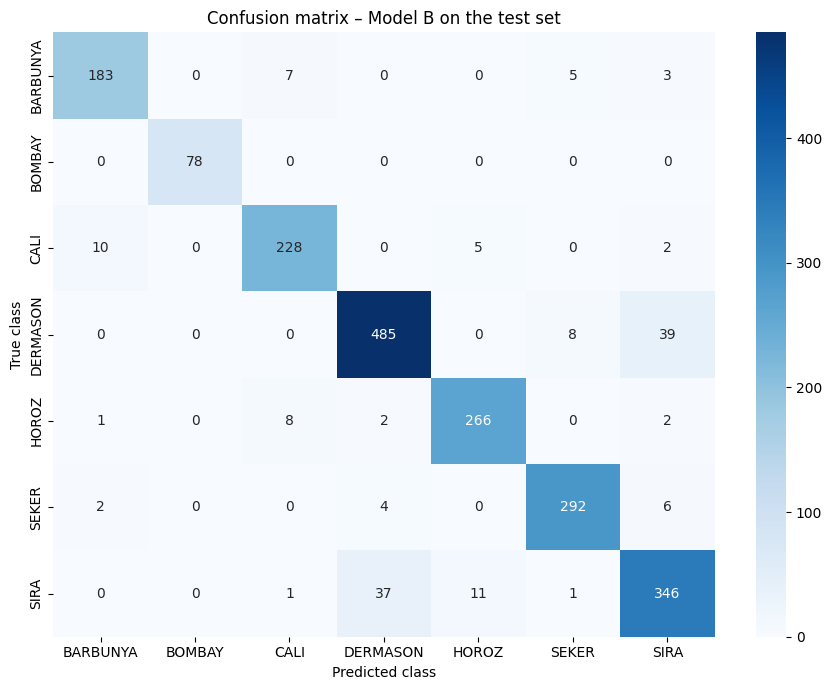

Most frequent errors (true -> predicted):
  DERMASON  -> SIRA     : 39
  SIRA      -> DERMASON : 37
  SIRA      -> HOROZ    : 11
  CALI      -> BARBUNYA : 10
  HOROZ     -> CALI     : 8
  DERMASON  -> SEKER    : 8


In [ ]:
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion matrix – Model B on the test set')
plt.xlabel('Predicted class')
plt.ylabel('True class')
plt.tight_layout()
plt.show()

# самые частые ошибки (пригодится для Error Analysis)
errors = []
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and cm[i, j] > 0:
            errors.append((cm[i, j], class_names[i], class_names[j]))
print("Most frequent errors (true -> predicted):")
for n, t, p in sorted(errors, reverse=True)[:6]:
    print(f"  {t:9s} -> {p:9s}: {n}")

In [ ]:
c1, c2 = 'DERMASON', 'SIRA'
i1, i2 = list(class_names).index(c1), list(class_names).index(c2)

print(f"{c1} predicted as {c2}: {cm[i1, i2]}")
print(f"{c2} predicted as {c1}: {cm[i2, i1]}")
mutual = cm[i1, i2] + cm[i2, i1]
total_err = cm.sum() - np.trace(cm)
print(f"Mutual errors: {mutual} of {total_err} total test errors ({mutual/total_err*100:.1f}%)\n")

feats = ['Area', 'Perimeter', 'AspectRatio', 'Roundness']
pair = df[df['Class'].isin([c1, c2])]

def overlap(a, b, bins=50):
    edges = np.histogram_bin_edges(np.concatenate([a, b]), bins=bins)
    pa, _ = np.histogram(a, bins=edges); pb, _ = np.histogram(b, bins=edges)
    return np.minimum(pa / pa.sum(), pb / pb.sum()).sum()

rows = []
for f in feats:
    a, b = pair.loc[pair['Class'] == c1, f], pair.loc[pair['Class'] == c2, f]
    rows.append({'Feature': f,
                 f'{c1} mean': a.mean(), f'{c1} std': a.std(),
                 f'{c2} mean': b.mean(), f'{c2} std': b.std(),
                 'Overlap': overlap(a, b)})
pd.DataFrame(rows).round(4)

DERMASON predicted as SIRA: 39
SIRA predicted as DERMASON: 37
Mutual errors: 76 of 154 total test errors (49.4%)



,Feature,DERMASON mean,DERMASON std,SIRA mean,SIRA std,Overlap
0,Area,32118.7109,4676.1295,44729.1286,4546.7699,0.1890
1,Perimeter,665.2095,50.4675,796.4187,44.3771,0.1719
2,AspectRatio,1.4905,0.0964,1.5701,0.0966,0.6688
3,Roundness,0.9081,0.0294,0.8847,0.0237,0.5367


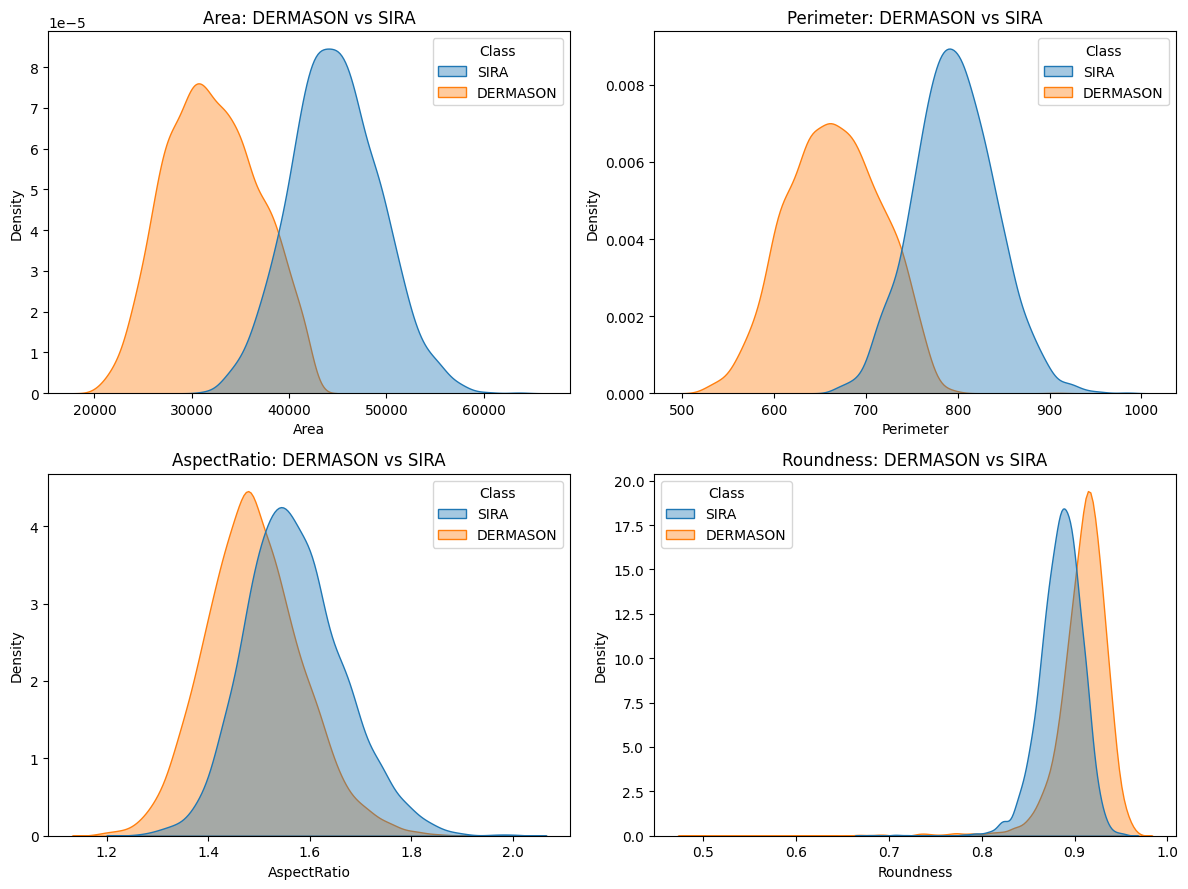

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, f in zip(axes.flat, feats):
    sns.kdeplot(data=pair, x=f, hue='Class', fill=True, common_norm=False,
                alpha=0.4, ax=ax)
    ax.set_title(f"{f}: {c1} vs {c2}")
plt.tight_layout()
plt.show()

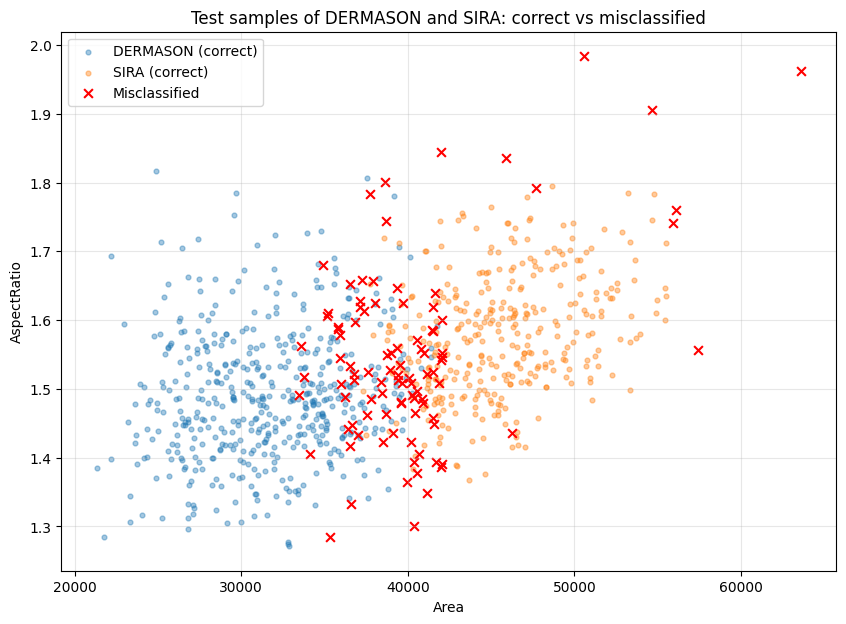

In [ ]:
mask = np.isin(y_test, [i1, i2])
X_pair = X_test[mask]
true_pair, pred_pair = y_test[mask], y_test_pred[mask]
ar_idx, area_idx = feats.index('AspectRatio'), None
cols = list(df.drop(columns='Class').columns)

plt.figure(figsize=(10, 7))
for cls, color in [(i1, 'tab:blue'), (i2, 'tab:orange')]:
    ok = (true_pair == cls) & (pred_pair == true_pair)
    plt.scatter(X_pair[ok, cols.index('Area')], X_pair[ok, cols.index('AspectRatio')],
                s=12, alpha=0.4, color=color, label=f"{class_names[cls]} (correct)")
wrong = pred_pair != true_pair
plt.scatter(X_pair[wrong, cols.index('Area')], X_pair[wrong, cols.index('AspectRatio')],
            s=40, color='red', marker='x', label='Misclassified')
plt.xlabel('Area'); plt.ylabel('AspectRatio')
plt.title(f'Test samples of {c1} and {c2}: correct vs misclassified')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [ ]:
optimizers = {
    'Adam (lr=0.001)':                 dict(opt_name='adam', lr=0.001),
    'SGD (lr=0.001)':                  dict(opt_name='sgd',  lr=0.001),
    'SGD (lr=0.01)':                   dict(opt_name='sgd',  lr=0.01),
    'SGD + momentum 0.9 (lr=0.01)':    dict(opt_name='sgd',  lr=0.01, momentum=0.9),
}

opt_results, opt_hist = [], {}
for name, params in optimizers.items():
    model, hist = train_model(X_train_scaled, y_train, X_val_scaled, y_val,
                              hidden=[32, 16], epochs=50, **params)
    y_pred = predict(model, X_val_scaled)
    opt_results.append({
        'Optimizer': name,
        'Val accuracy': accuracy_score(y_val, y_pred),
        'Val Macro F1': f1_score(y_val, y_pred, average='macro'),
        'Final train loss': hist['train_loss'][-1],
        'Final val loss': hist['val_loss'][-1],
        'Epoch to 90% val acc': first_epoch_reaching(hist, 0.90),
        'Best epoch (min val loss)': int(np.argmin(hist['val_loss'])) + 1,
    })
    opt_hist[name] = hist

opt_df = pd.DataFrame(opt_results)
opt_df.round(4)

,Optimizer,Val accuracy,Val Macro F1,Final train loss,Final val loss,Epoch to 90% val acc,Best epoch (min val loss)
0,Adam (lr=0.001),0.9276,0.9364,0.1671,0.2073,3,46
1,SGD (lr=0.001),0.6992,0.6219,0.7854,0.7944,never,50
2,SGD (lr=0.01),0.9197,0.9283,0.2021,0.2190,17,50
3,SGD + momentum 0.9 (lr=0.01),0.9301,0.9387,0.1656,0.2019,2,36


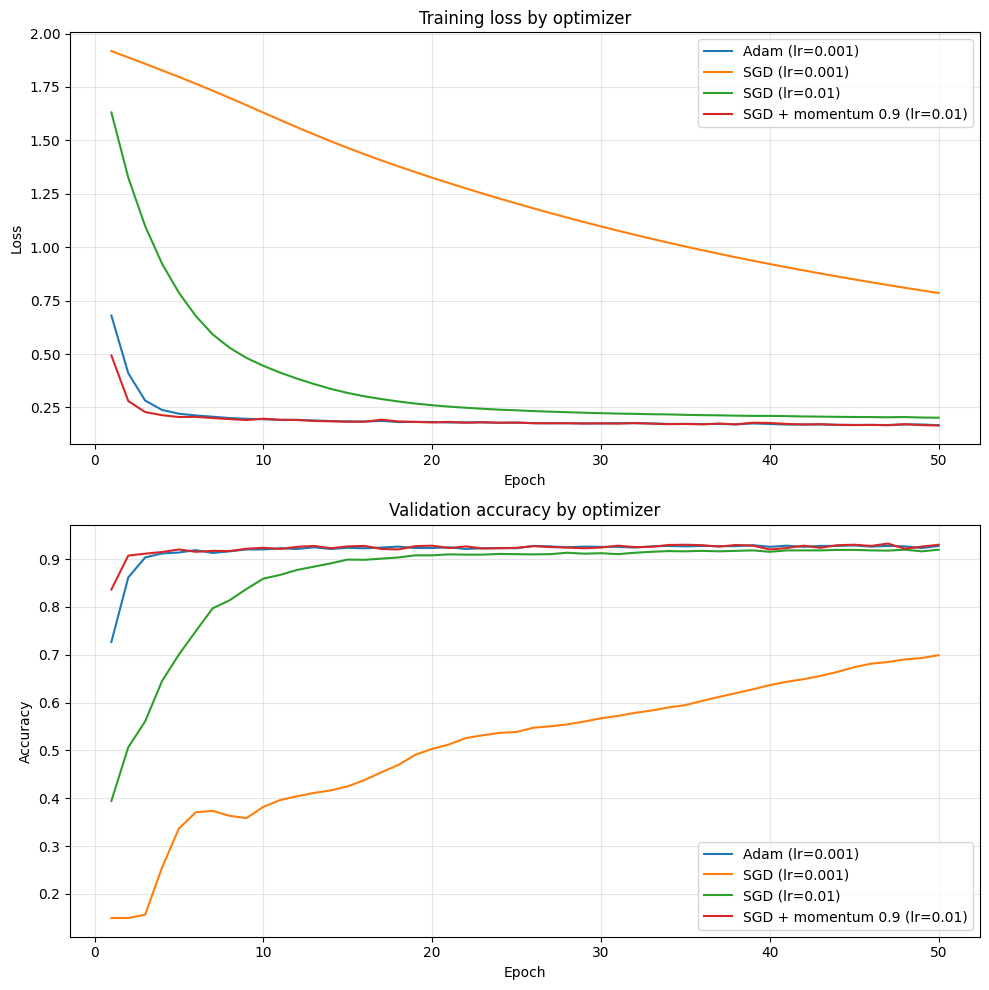

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))
for name, hist in opt_hist.items():
    ep = range(1, len(hist['val_loss']) + 1)
    axes[0].plot(ep, hist['train_loss'], label=name)
    axes[1].plot(ep, hist['val_acc'], label=name)

axes[0].set_title('Training loss by optimizer'); axes[0].set_ylabel('Loss')
axes[1].set_title('Validation accuracy by optimizer'); axes[1].set_ylabel('Accuracy')
for ax in axes:
    ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()